In [3]:
import pandas as pd

file_path = "Raisin_Dataset.xlsx"
pandas_df = pd.read_excel(file_path)

print("Dataset shape:", pandas_df.shape)
pandas_df.head()

Dataset shape: (900, 8)


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [4]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("RaisinClassification")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.3


In [6]:
spark_df = spark.createDataFrame(pandas_df)

print("Total rows:", spark_df.count())
print("Total columns:", len(spark_df.columns))

spark_df.show(5)
spark_df.printSchema()

Total rows: 900
Total columns: 8
+-----+---------------+---------------+------------+----------+-----------+---------+-------+
| Area|MajorAxisLength|MinorAxisLength|Eccentricity|ConvexArea|     Extent|Perimeter|  Class|
+-----+---------------+---------------+------------+----------+-----------+---------+-------+
|87524|    442.2460114|     253.291155| 0.819738392|     90546|0.758650579|  1184.04|Kecimen|
|75166|     406.690687|    243.0324363| 0.801805234|     78789| 0.68412957| 1121.786|Kecimen|
|90856|    442.2670483|    266.3283177| 0.798353619|     93717|0.637612812| 1208.575|Kecimen|
|45928|    286.5405586|    208.7600423| 0.684989217|     47336|0.699599385|  844.162|Kecimen|
|79408|    352.1907699|    290.8275329|  0.56401133|     81463|0.792771926| 1073.251|Kecimen|
+-----+---------------+---------------+------------+----------+-----------+---------+-------+
only showing top 5 rows

root
 |-- Area: long (nullable = true)
 |-- MajorAxisLength: double (nullable = true)
 |-- Minor

In [7]:
from pyspark.sql.functions import col, sum

missing_values = spark_df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in spark_df.columns
])

missing_values.show()

+----+---------------+---------------+------------+----------+------+---------+-----+
|Area|MajorAxisLength|MinorAxisLength|Eccentricity|ConvexArea|Extent|Perimeter|Class|
+----+---------------+---------------+------------+----------+------+---------+-----+
|   0|              0|              0|           0|         0|     0|        0|    0|
+----+---------------+---------------+------------+----------+------+---------+-----+



In [8]:
total_rows = spark_df.count()
unique_rows = spark_df.dropDuplicates().count()

print("Total rows:", total_rows)
print("Unique rows:", unique_rows)
print("Duplicate rows:", total_rows - unique_rows)

Total rows: 900
Unique rows: 900
Duplicate rows: 0


In [9]:
spark_df.groupBy("Class").count().show()

+-------+-----+
|  Class|count|
+-------+-----+
|Kecimen|  450|
|  Besni|  450|
+-------+-----+



In [10]:
spark_df.printSchema()

root
 |-- Area: long (nullable = true)
 |-- MajorAxisLength: double (nullable = true)
 |-- MinorAxisLength: double (nullable = true)
 |-- Eccentricity: double (nullable = true)
 |-- ConvexArea: long (nullable = true)
 |-- Extent: double (nullable = true)
 |-- Perimeter: double (nullable = true)
 |-- Class: string (nullable = true)



In [11]:
spark_df.describe().show()

26/10/18 07:41:23 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+-----------------+------------------+------------------+-------------------+-----------------+--------------------+------------------+-------+
|summary|             Area|   MajorAxisLength|   MinorAxisLength|       Eccentricity|       ConvexArea|              Extent|         Perimeter|  Class|
+-------+-----------------+------------------+------------------+-------------------+-----------------+--------------------+------------------+-------+
|  count|              900|               900|               900|                900|              900|                 900|               900|    900|
|   mean|87804.12777777777|430.92995049844444|254.48813290322227| 0.7815421500333333|         91186.09|  0.6995079264077777|1165.9066355555556|   NULL|
| stddev|39002.11139007148|116.03512062468941|49.988901705717616|0.09031840993160663|40769.29013198777|0.053468200288159275| 273.7643154160195|   NULL|
|    min|            25387|        225.629541|       143.7108718|        0.348729642|   

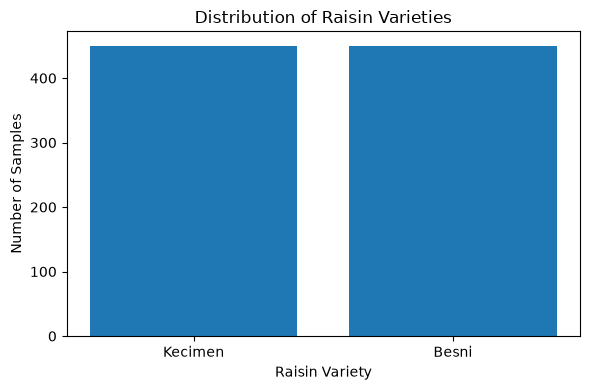

In [12]:
import matplotlib.pyplot as plt

class_counts = (
    spark_df.groupBy("Class")
    .count()
    .toPandas()
)

plt.figure(figsize=(6, 4))
plt.bar(class_counts["Class"], class_counts["count"])
plt.title("Distribution of Raisin Varieties")
plt.xlabel("Raisin Variety")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()